# Cell Ranger Versions - Scanorama Default vs Best UMAP

Fixed seed: `4`. Left column: cell type. Right column: batch.
Default is the top row and Best is the bottom row. Each column uses one shared legend.

Selection deltas for this seed: bio `+0.005195`,
batch `+0.144119`, joint `+0.060764`.


In [1]:
import gc
import os
import sys

os.environ["PYTHONNOUSERSITE"] = "1"
sys.path = [
    path
    for path in sys.path
    if ".local/lib/python3.10/site-packages" not in path
]

PROJECT_ROOT = (
    "/ubc/cs/research/beaver/projects/"
    "Single-cell-integration-metrics"
)
os.environ["R_HOME"] = (
    f"{PROJECT_ROOT}/CondaEnv/harmony_optuna/lib/R"
)
sys.path.insert(0, f"{PROJECT_ROOT}/scib/")

import anndata as ad
import numpy as np
import pandas as pd
import scanorama
import scanpy as sc
import scipy.sparse as sp

from scib.metrics.metrics import metrics


In [2]:
DATASET_NAME = 'cellranger_versions'
DATA_PATH = f"{PROJECT_ROOT}/data/{DATASET_NAME}.h5ad"
BATCH_KEY = 'batch'
LABEL_KEY = 'cell_type'

SELECTED_BIO_METRICS = ('BAMI', 'CASW', 'SCGRAPHM')
SELECTED_BATCH_METRICS = ('BRAS', 'KBET', 'CPCR')
SELECTED_METRICS = SELECTED_BIO_METRICS + SELECTED_BATCH_METRICS

N_SEEDS = 10
N_NEIGHBORS = 15
N_TOP_HVG = 2000
INTERNAL_DIMRED = 50
BATCH_SIZE = 5000
APPROX = True
UNION = False

EMBED_KEY = "X_scanorama"
CLUSTER_KEY = "leiden_opt"
METRIC_BATCH_KEY = "scanorama_metric_batch"
METRIC_LABEL_KEY = "scanorama_metric_label"

assert DATASET_NAME == 'cellranger_versions'
assert BATCH_KEY == 'batch'
assert LABEL_KEY == 'cell_type'
assert SELECTED_METRICS == ('BAMI', 'CASW', 'SCGRAPHM', 'BRAS', 'KBET', 'CPCR')

pd.Series(
    {
        "dataset": DATASET_NAME,
        "data_path": DATA_PATH,
        "batch_key": BATCH_KEY,
        "label_key": LABEL_KEY,
        "metrics": list(SELECTED_METRICS),
        "seeds": list(range(N_SEEDS)),
        "internal_dimred": INTERNAL_DIMRED,
        "batch_size": BATCH_SIZE,
        "n_top_hvg": N_TOP_HVG,
    },
    name="configuration",
)


dataset                                          cellranger_versions
data_path          /ubc/cs/research/beaver/projects/Single-cell-i...
batch_key                                                      batch
label_key                                                  cell_type
metrics                     [BAMI, CASW, SCGRAPHM, BRAS, KBET, CPCR]
seeds                                 [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
internal_dimred                                                   50
batch_size                                                      5000
n_top_hvg                                                       2000
Name: configuration, dtype: object

In [3]:
from pathlib import Path
import anndata as ad
import matplotlib.pyplot as plt
import scanpy as sc
from IPython.display import Image, display
from matplotlib.lines import Line2D

METHOD_NAME = 'Scanorama'
DATASET_DISPLAY = 'Cellranger versions'
SEED = 4
UMAP_ROOT = Path(
    PROJECT_ROOT,
    "notebooks",
    "optuna_multimetrics_tests",
    "UMAP",
)
FIGURE_ROOT = UMAP_ROOT / "figures"
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)
FIGURE_STEM = 'cellranger_versions_scanorama_seed4_default_vs_best_umap'
PNG_PATH = FIGURE_ROOT / f"{FIGURE_STEM}.png"
SVG_PATH = FIGURE_ROOT / f"{FIGURE_STEM}.svg"

assert DATASET_NAME == 'cellranger_versions'
assert SEED == 4

pd.Series(
    {
        "dataset": DATASET_NAME,
        "method": METHOD_NAME,
        "seed": SEED,
        "cell_type_key": LABEL_KEY,
        "batch_key": BATCH_KEY,
        "embedding_key": EMBED_KEY,
        "png": str(PNG_PATH),
        "svg": str(SVG_PATH),
    },
    name="umap_configuration",
)


dataset                                        cellranger_versions
method                                                   Scanorama
seed                                                             4
cell_type_key                                            cell_type
batch_key                                                    batch
embedding_key                                          X_scanorama
png              /ubc/cs/research/beaver/projects/Single-cell-i...
svg              /ubc/cs/research/beaver/projects/Single-cell-i...
Name: umap_configuration, dtype: object

In [4]:
def validate_dataset_contents():
    adata_backed = ad.read_h5ad(DATA_PATH, backed="r")
    try:
        required_keys = (BATCH_KEY, LABEL_KEY)
        missing_keys = [
            key for key in required_keys if key not in adata_backed.obs
        ]
        if missing_keys:
            raise ValueError(
                f"Missing obs keys {missing_keys}. "
                f"Available keys: {list(adata_backed.obs.columns)}"
            )

        obs = adata_backed.obs[[BATCH_KEY, LABEL_KEY]].copy()
        pseudotime = None
        if "TRAJ" in SELECTED_METRICS:
            if "dpt_pseudotime" not in adata_backed.obs:
                raise ValueError(
                    "TRAJ requires adata.obs['dpt_pseudotime']."
                )
            pseudotime = adata_backed.obs["dpt_pseudotime"].copy()

        n_obs = int(adata_backed.n_obs)
        n_vars = int(adata_backed.n_vars)
    finally:
        adata_backed.file.close()

    if obs.isna().any().any():
        raise ValueError(
            "Missing batch/label values: "
            f"{obs.isna().sum().to_dict()}"
        )

    n_batches = int(obs[BATCH_KEY].nunique())
    n_labels = int(obs[LABEL_KEY].nunique())
    if n_batches < 2:
        raise ValueError(
            f"Batch metrics require at least 2 batches; found {n_batches}."
        )

    batch_coverage = obs.groupby(
        LABEL_KEY,
        observed=True,
    )[BATCH_KEY].nunique()
    label_counts = obs.groupby(LABEL_KEY, observed=True).size()

    if "TRAJ" in SELECTED_METRICS:
        finite_pseudotime = pseudotime.dropna()
        if (
            len(finite_pseudotime) < 2
            or finite_pseudotime.nunique() < 2
        ):
            raise ValueError(
                "TRAJ requires at least 2 usable pseudotime values."
            )

    if "ISOLISI" in SELECTED_METRICS:
        min_batch_coverage = int(batch_coverage.min())
        if min_batch_coverage >= n_batches:
            raise ValueError(
                "ISOLISI is enabled, but every label appears in all batches."
            )

    eligible_cpcr_labels = [
        str(label)
        for label in label_counts.index
        if int(label_counts.loc[label]) >= 100
        and int(batch_coverage.loc[label]) >= 2
    ]
    if "CPCR" in SELECTED_METRICS and not eligible_cpcr_labels:
        raise ValueError(
            "CPCR requires a label with at least 100 cells across "
            "at least 2 batches."
        )

    return {
        "n_obs": n_obs,
        "n_vars": n_vars,
        "n_batches": n_batches,
        "n_labels": n_labels,
        "cpcr_eligible_labels": len(eligible_cpcr_labels),
    }


validate_dataset_contents()


{'n_obs': 19202,
 'n_vars': 22742,
 'n_batches': 2,
 'n_labels': 15,
 'cpcr_eligible_labels': 12}

In [5]:
SCANORAMA_PARAMS = {'knn': 20, 'sigma': 15.0, 'alpha': 0.1}
assert tuple(SCANORAMA_PARAMS) == ("knn", "sigma", "alpha")

pd.Series(
    {
        **SCANORAMA_PARAMS,
        "batch_size": BATCH_SIZE,
        "approx": APPROX,
        "union": UNION,
        "internal_dimred": INTERNAL_DIMRED,
        "n_top_hvg": N_TOP_HVG,
    },
    name="default_setting",
)

def check_keys(adata):
    missing_keys = [
        key
        for key in (BATCH_KEY, LABEL_KEY)
        if key not in adata.obs
    ]
    if missing_keys:
        raise ValueError(
            f"Missing keys in adata.obs: {missing_keys}. "
            f"Available keys: {list(adata.obs.columns)}"
        )


def ensure_csr(matrix):
    if sp.issparse(matrix):
        return matrix.tocsr()
    return sp.csr_matrix(matrix)


def split_by_batch(adata):
    batches = adata.obs[BATCH_KEY].astype("category")
    batch_names = list(batches.cat.categories)
    parts = []
    index_parts = []

    for batch_name in batch_names:
        indices = np.where(batches.values == batch_name)[0]
        index_parts.append(indices)
        parts.append(adata[indices, :].copy())

    return parts, batch_names, index_parts


def hvg_subset(adata):
    if "highly_variable" not in adata.var:
        sc.pp.highly_variable_genes(
            adata,
            flavor="seurat",
            n_top_genes=N_TOP_HVG,
        )

    hvg_mask = (
        adata.var["highly_variable"]
        .fillna(False)
        .astype(bool)
        .to_numpy()
    )
    if int(hvg_mask.sum()) == 0:
        raise ValueError("No highly variable genes selected.")
    return adata[:, hvg_mask].copy()


def reassemble_scanorama_embedding(parts, index_parts, n_obs):
    embedding_concat = np.concatenate(
        [part.obsm[EMBED_KEY] for part in parts],
        axis=0,
    )
    concat_indices = np.concatenate(index_parts)
    inverse = np.empty(n_obs, dtype=np.int64)
    inverse[concat_indices] = np.arange(n_obs, dtype=np.int64)
    return embedding_concat[inverse, :]


def run_scanorama_setting(adata, seed):
    np.random.seed(seed)
    check_keys(adata)

    adata_work = hvg_subset(adata.copy())
    adata_work.X = ensure_csr(adata_work.X)
    parts, batch_names, index_parts = split_by_batch(adata_work)

    scanorama.integrate_scanpy(
        parts,
        batch_size=BATCH_SIZE,
        verbose=0,
        ds_names=batch_names,
        dimred=INTERNAL_DIMRED,
        approx=APPROX,
        sigma=float(SCANORAMA_PARAMS["sigma"]),
        alpha=float(SCANORAMA_PARAMS["alpha"]),
        knn=int(SCANORAMA_PARAMS["knn"]),
        union=UNION,
        hvg=None,
        seed=int(seed),
    )

    embedding = reassemble_scanorama_embedding(
        parts,
        index_parts,
        n_obs=adata_work.n_obs,
    )
    if embedding.shape[0] != adata_work.n_obs:
        raise ValueError(
            f"Scanorama output shape {embedding.shape} is incompatible "
            f"with n_obs={adata_work.n_obs}."
        )
    if not np.all(np.isfinite(embedding)):
        raise ValueError(
            "Scanorama produced NaN or Inf in X_scanorama."
        )

    adata_int = adata_work.copy()
    adata_int.obsm[EMBED_KEY] = np.asarray(
        embedding,
        dtype=np.float32,
    )
    return adata_int


In [6]:
print(f"Running Default with seed {SEED}", flush=True)
adata_default = run_scanorama_setting(
    ad.read_h5ad(DATA_PATH),
    seed=SEED,
)
assert EMBED_KEY in adata_default.obsm
assert adata_default.obsm[EMBED_KEY].shape[0] == adata_default.n_obs
assert np.isfinite(adata_default.obsm[EMBED_KEY]).all()
adata_default


Running Default with seed 4


After v6: 3382 genes
After v8: 3382 genes
Found 3382 genes among all datasets


AnnData object with n_obs × n_vars = 19202 × 3382
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'n_genes', 'n_counts', 'cell_type', 'batch'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'cell_type_colors', 'hvg', 'neighbors', 'pca', 'species', 'umap'
    obsm: 'X_pca', 'X_umap', 'X_scanorama'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [7]:
OPTUNA_BEST_SOURCE = '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/optuna_multi_metrics/scanorama/cellranger_versions/expanded_metrics_v2/scanorama_cellranger_versions_joint_expanded_metrics_v2_best_params.json'
OPTUNA_STUDY_NAME = 'scanorama_cellranger_versions_joint_expanded_metrics_v2'
OPTUNA_BEST_TRIAL = 131
OPTUNA_BEST_VALUE = 0.7430731944746773
OPTUNA_BEST_PARAMS = {'knn': 50, 'sigma': 59.80765621156959, 'alpha': 0.36097085034101817}

assert tuple(OPTUNA_BEST_PARAMS) == ("knn", "sigma", "alpha")
SCANORAMA_PARAMS = dict(OPTUNA_BEST_PARAMS)

pd.Series(
    {
        "source": OPTUNA_BEST_SOURCE,
        "study": OPTUNA_STUDY_NAME,
        "best_trial": OPTUNA_BEST_TRIAL,
        "best_value": OPTUNA_BEST_VALUE,
        **SCANORAMA_PARAMS,
        "batch_size": BATCH_SIZE,
        "approx": APPROX,
        "union": UNION,
        "internal_dimred": INTERNAL_DIMRED,
        "n_top_hvg": N_TOP_HVG,
    },
    name="best_setting",
)

def check_keys(adata):
    missing_keys = [
        key
        for key in (BATCH_KEY, LABEL_KEY)
        if key not in adata.obs
    ]
    if missing_keys:
        raise ValueError(
            f"Missing keys in adata.obs: {missing_keys}. "
            f"Available keys: {list(adata.obs.columns)}"
        )


def ensure_csr(matrix):
    if sp.issparse(matrix):
        return matrix.tocsr()
    return sp.csr_matrix(matrix)


def split_by_batch(adata):
    batches = adata.obs[BATCH_KEY].astype("category")
    batch_names = list(batches.cat.categories)
    parts = []
    index_parts = []

    for batch_name in batch_names:
        indices = np.where(batches.values == batch_name)[0]
        index_parts.append(indices)
        parts.append(adata[indices, :].copy())

    return parts, batch_names, index_parts


def hvg_subset(adata):
    if "highly_variable" not in adata.var:
        sc.pp.highly_variable_genes(
            adata,
            flavor="seurat",
            n_top_genes=N_TOP_HVG,
        )

    hvg_mask = (
        adata.var["highly_variable"]
        .fillna(False)
        .astype(bool)
        .to_numpy()
    )
    if int(hvg_mask.sum()) == 0:
        raise ValueError("No highly variable genes selected.")
    return adata[:, hvg_mask].copy()


def reassemble_scanorama_embedding(parts, index_parts, n_obs):
    embedding_concat = np.concatenate(
        [part.obsm[EMBED_KEY] for part in parts],
        axis=0,
    )
    concat_indices = np.concatenate(index_parts)
    inverse = np.empty(n_obs, dtype=np.int64)
    inverse[concat_indices] = np.arange(n_obs, dtype=np.int64)
    return embedding_concat[inverse, :]


def run_scanorama_setting(adata, seed):
    np.random.seed(seed)
    check_keys(adata)

    adata_work = hvg_subset(adata.copy())
    adata_work.X = ensure_csr(adata_work.X)
    parts, batch_names, index_parts = split_by_batch(adata_work)

    scanorama.integrate_scanpy(
        parts,
        batch_size=BATCH_SIZE,
        verbose=0,
        ds_names=batch_names,
        dimred=INTERNAL_DIMRED,
        approx=APPROX,
        sigma=float(SCANORAMA_PARAMS["sigma"]),
        alpha=float(SCANORAMA_PARAMS["alpha"]),
        knn=int(SCANORAMA_PARAMS["knn"]),
        union=UNION,
        hvg=None,
        seed=int(seed),
    )

    embedding = reassemble_scanorama_embedding(
        parts,
        index_parts,
        n_obs=adata_work.n_obs,
    )
    if embedding.shape[0] != adata_work.n_obs:
        raise ValueError(
            f"Scanorama output shape {embedding.shape} is incompatible "
            f"with n_obs={adata_work.n_obs}."
        )
    if not np.all(np.isfinite(embedding)):
        raise ValueError(
            "Scanorama produced NaN or Inf in X_scanorama."
        )

    adata_int = adata_work.copy()
    adata_int.obsm[EMBED_KEY] = np.asarray(
        embedding,
        dtype=np.float32,
    )
    return adata_int


In [8]:
print(f"Running Best with seed {SEED}", flush=True)
adata_best = run_scanorama_setting(
    ad.read_h5ad(DATA_PATH),
    seed=SEED,
)
assert EMBED_KEY in adata_best.obsm
assert adata_best.obsm[EMBED_KEY].shape[0] == adata_best.n_obs
assert np.isfinite(adata_best.obsm[EMBED_KEY]).all()
adata_best


Running Best with seed 4


After v6: 3382 genes
After v8: 3382 genes
Found 3382 genes among all datasets


AnnData object with n_obs × n_vars = 19202 × 3382
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'n_genes', 'n_counts', 'cell_type', 'batch'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'cell_type_colors', 'hvg', 'neighbors', 'pca', 'species', 'umap'
    obsm: 'X_pca', 'X_umap', 'X_scanorama'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [9]:
assert adata_default.obs_names.equals(adata_best.obs_names)
assert LABEL_KEY in adata_default.obs
assert BATCH_KEY in adata_default.obs
assert adata_default.obs[LABEL_KEY].equals(adata_best.obs[LABEL_KEY])
assert adata_default.obs[BATCH_KEY].equals(adata_best.obs[BATCH_KEY])

for setting_name, adata_setting in (
    ("Default", adata_default),
    ("Best", adata_best),
):
    sc.pp.neighbors(
        adata_setting,
        n_neighbors=N_NEIGHBORS,
        use_rep=EMBED_KEY,
        random_state=SEED,
    )
    sc.tl.umap(adata_setting, random_state=SEED)
    assert "X_umap" in adata_setting.obsm
    assert np.isfinite(adata_setting.obsm["X_umap"]).all()
    print(
        setting_name,
        adata_setting.obsm["X_umap"].shape,
        flush=True,
    )


Default (19202, 2)


Best (19202, 2)


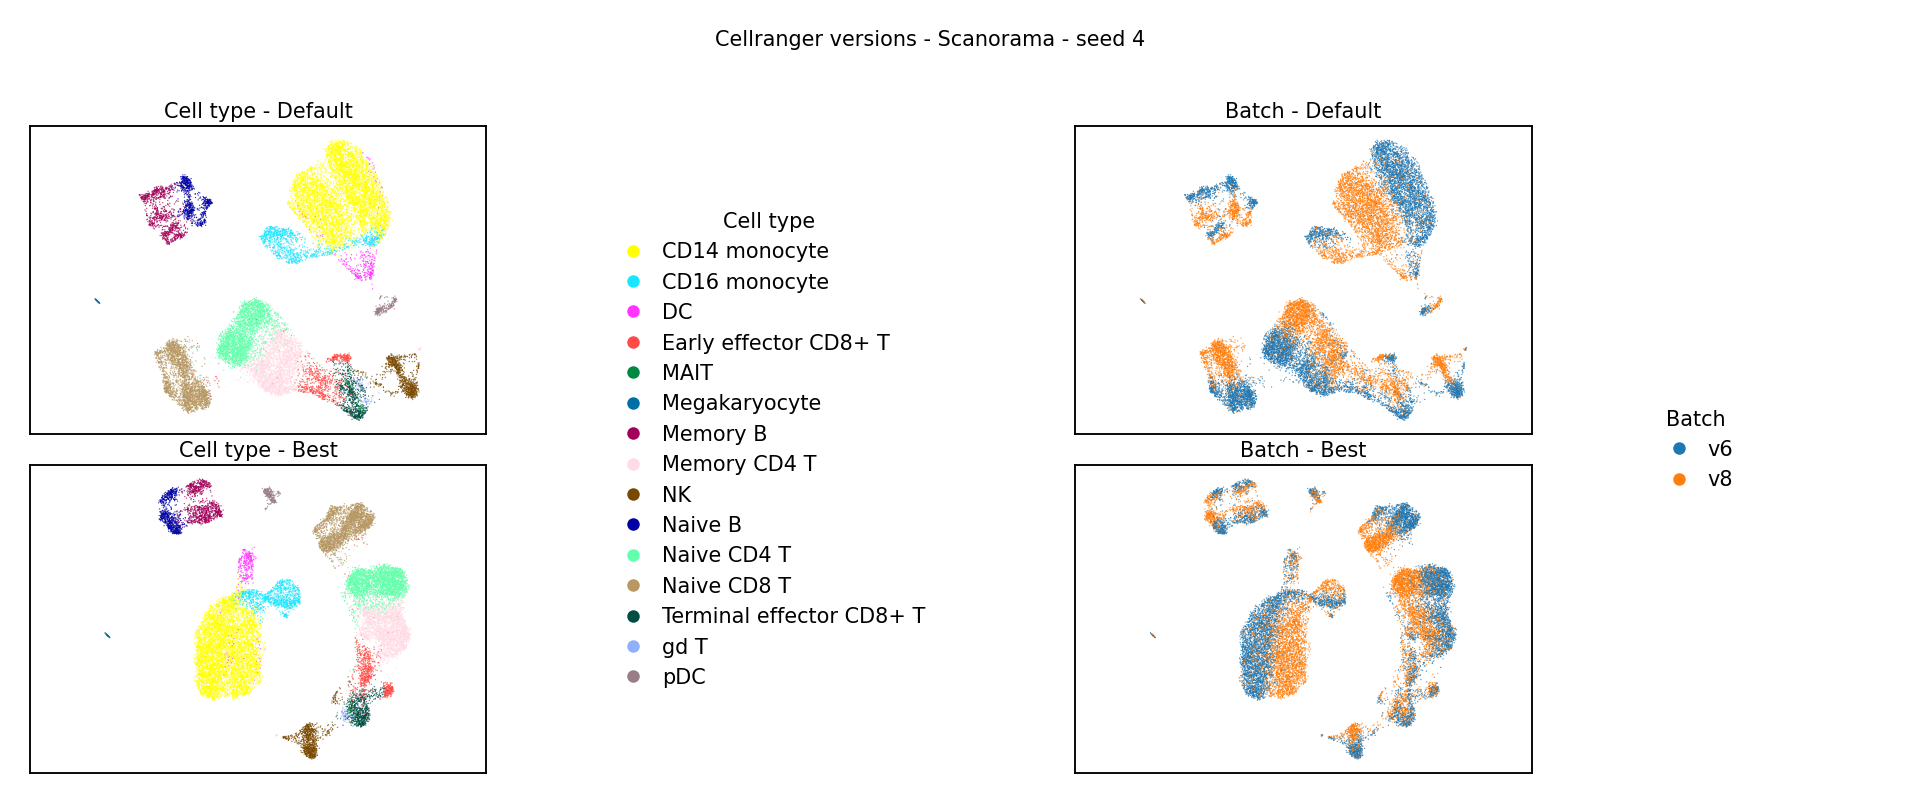

png           /ubc/cs/research/beaver/projects/Single-cell-i...
svg           /ubc/cs/research/beaver/projects/Single-cell-i...
n_cells                                                   19202
cell_types                                                   15
batches                                                       2
point_size                                                  0.1
Name: saved_figure, dtype: object

In [10]:
UMAP_SOURCE_TEXT_SIZE_PT = 5.0
UMAP_RASTER_DPI = 600


def ordered_categories(adata, key):
    values = adata.obs[key].astype(str)
    return tuple(sorted(pd.unique(values), key=str))


def category_palette(categories):
    if len(categories) <= len(sc.pl.palettes.default_102):
        colors = sc.pl.palettes.default_102[: len(categories)]
    else:
        cmap = plt.get_cmap("hsv", len(categories))
        colors = [cmap(index) for index in range(len(categories))]
    return dict(zip(categories, colors))


def scatter_panel(ax, adata, key, palette, title, order, point_size):
    values = adata.obs[key].astype(str).to_numpy()
    coordinates = adata.obsm["X_umap"]
    colors = [palette[value] for value in values[order]]
    ax.scatter(
        coordinates[order, 0],
        coordinates[order, 1],
        c=colors,
        s=point_size,
        alpha=0.78,
        linewidths=0,
        rasterized=False,
    )
    ax.set_title(
        title,
        fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
        pad=2,
    )
    ax.set_aspect("equal", adjustable="datalim")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.45)


def legend_handles(categories, palette):
    return [
        Line2D(
            [0],
            [0],
            marker="o",
            color="none",
            markerfacecolor=palette[category],
            markeredgecolor="none",
            markersize=3,
            label=category,
        )
        for category in categories
    ]


cell_categories = ordered_categories(adata_default, LABEL_KEY)
batch_categories = ordered_categories(adata_default, BATCH_KEY)
cell_palette = category_palette(cell_categories)
tab10_batch_colors = plt.get_cmap("tab10").colors
if len(batch_categories) > len(tab10_batch_colors):
    raise ValueError(
        "tab10 does not contain enough colors for all batch categories."
    )
batch_palette = dict(
    zip(batch_categories, tab10_batch_colors)
)

cell_legend_columns = 2 if len(cell_categories) > 18 else 1
batch_legend_columns = 2 if len(batch_categories) > 18 else 1
max_legend_rows = max(
    int(np.ceil(len(cell_categories) / cell_legend_columns)),
    int(np.ceil(len(batch_categories) / batch_legend_columns)),
)
figure_height = max(2.8, 0.18 * max_legend_rows)
figure = plt.figure(figsize=(8.0, figure_height), dpi=250)
grid = figure.add_gridspec(
    2,
    4,
    width_ratios=(1.0, 0.82, 1.0, 0.55),
    hspace=0.10,
    wspace=0.28,
)
cell_default_axis = figure.add_subplot(grid[0, 0])
cell_best_axis = figure.add_subplot(grid[1, 0])
cell_legend_axis = figure.add_subplot(grid[:, 1])
batch_default_axis = figure.add_subplot(grid[0, 2])
batch_best_axis = figure.add_subplot(grid[1, 2])
batch_legend_axis = figure.add_subplot(grid[:, 3])

plot_order = np.random.default_rng(SEED).permutation(
    adata_default.n_obs
)
if adata_default.n_obs <= 20_000:
    point_size = 0.10
elif adata_default.n_obs <= 40_000:
    point_size = 0.07
elif adata_default.n_obs <= 100_000:
    point_size = 0.05
else:
    point_size = 0.03

scatter_panel(
    cell_default_axis,
    adata_default,
    LABEL_KEY,
    cell_palette,
    "Cell type - Default",
    plot_order,
    point_size,
)
scatter_panel(
    cell_best_axis,
    adata_best,
    LABEL_KEY,
    cell_palette,
    "Cell type - Best",
    plot_order,
    point_size,
)
scatter_panel(
    batch_default_axis,
    adata_default,
    BATCH_KEY,
    batch_palette,
    "Batch - Default",
    plot_order,
    point_size,
)
scatter_panel(
    batch_best_axis,
    adata_best,
    BATCH_KEY,
    batch_palette,
    "Batch - Best",
    plot_order,
    point_size,
)

cell_legend_axis.axis("off")
cell_legend_axis.legend(
    handles=legend_handles(cell_categories, cell_palette),
    title="Cell type",
    loc="center left",
    frameon=False,
    fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    title_fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    ncol=cell_legend_columns,
    columnspacing=0.9,
    handletextpad=0.4,
)
batch_legend_axis.axis("off")
batch_legend_axis.legend(
    handles=legend_handles(batch_categories, batch_palette),
    title="Batch",
    loc="center left",
    frameon=False,
    fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    title_fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    ncol=batch_legend_columns,
    columnspacing=0.9,
    handletextpad=0.4,
)

figure.suptitle(
    f"{DATASET_DISPLAY} - {METHOD_NAME} - seed {SEED}",
    fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    y=0.995,
)
figure.savefig(
    PNG_PATH,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
figure.savefig(
    SVG_PATH,
    format="svg",
    dpi=UMAP_RASTER_DPI,
    bbox_inches="tight",
    facecolor="white",
)
plt.close(figure)

display(Image(filename=str(PNG_PATH)))
pd.Series(
    {
        "png": str(PNG_PATH),
        "svg": str(SVG_PATH),
        "n_cells": adata_default.n_obs,
        "cell_types": len(cell_categories),
        "batches": len(batch_categories),
        "point_size": point_size,
    },
    name="saved_figure",
)


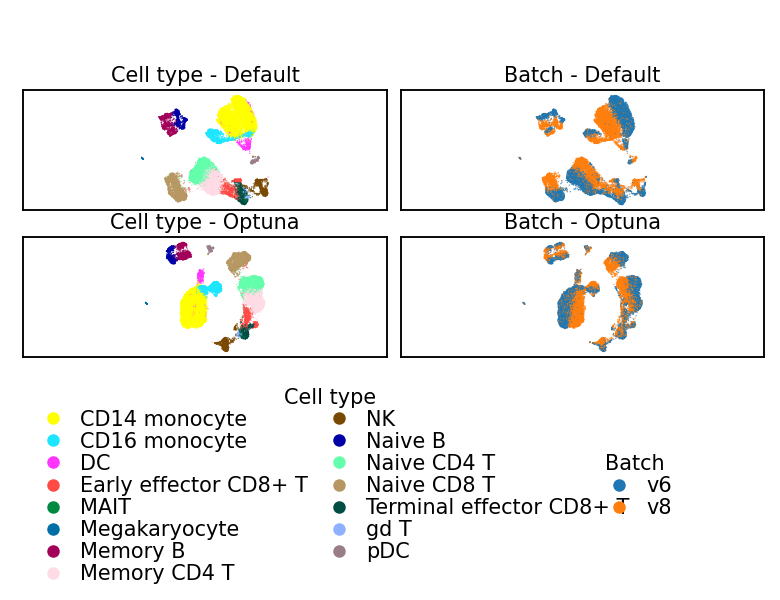

png            /ubc/cs/research/beaver/projects/Single-cell-i...
svg            /ubc/cs/research/beaver/projects/Single-cell-i...
n_cells                                                    19202
cell_types                                                    15
batches                                                        2
point_size                                                   0.1
panel_label                                               Optuna
suptitle                                                   False
Name: saved_revised_figure, dtype: object

In [11]:
revised_figure = plt.figure(
    figsize=(6.5 / 2.5, 2.0),
    dpi=250,
)
revised_grid = revised_figure.add_gridspec(
    3,
    4,
    height_ratios=(1.0, 1.0, 1.7),
    width_ratios=(1.0, 1.0, 1.0, 1.0),
    hspace=0.18,
    wspace=0.08,
)
revised_cell_default_axis = revised_figure.add_subplot(revised_grid[0, 0:2])
revised_cell_optuna_axis = revised_figure.add_subplot(revised_grid[1, 0:2])
revised_cell_legend_axis = revised_figure.add_subplot(revised_grid[2, 0:3])
revised_batch_default_axis = revised_figure.add_subplot(revised_grid[0, 2:4])
revised_batch_optuna_axis = revised_figure.add_subplot(revised_grid[1, 2:4])
revised_batch_legend_axis = revised_figure.add_subplot(revised_grid[2, 3])

scatter_panel(
    revised_cell_default_axis,
    adata_default,
    LABEL_KEY,
    cell_palette,
    "Cell type - Default",
    plot_order,
    point_size,
)
scatter_panel(
    revised_cell_optuna_axis,
    adata_best,
    LABEL_KEY,
    cell_palette,
    "Cell type - Optuna",
    plot_order,
    point_size,
)
scatter_panel(
    revised_batch_default_axis,
    adata_default,
    BATCH_KEY,
    batch_palette,
    "Batch - Default",
    plot_order,
    point_size,
)
scatter_panel(
    revised_batch_optuna_axis,
    adata_best,
    BATCH_KEY,
    batch_palette,
    "Batch - Optuna",
    plot_order,
    point_size,
)

revised_cell_legend_axis.axis("off")
revised_cell_legend_axis.legend(
    handles=legend_handles(cell_categories, cell_palette),
    title="Cell type",
    loc="center left",
    frameon=False,
    fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    title_fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    ncol=2,
    columnspacing=0.5,
    handletextpad=0.3,
    labelspacing=0.1,
    borderaxespad=0,
)
revised_batch_legend_axis.axis("off")
revised_batch_legend_axis.legend(
    handles=legend_handles(batch_categories, batch_palette),
    title="Batch",
    loc="center left",
    frameon=False,
    fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    title_fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    ncol=batch_legend_columns,
    columnspacing=0.5,
    handletextpad=0.3,
    labelspacing=0.1,
    borderaxespad=0,
)

REVISED_FIGURE_STEM = f"{FIGURE_STEM}_optuna_no_suptitle"
REVISED_PNG_PATH = FIGURE_ROOT / f"{REVISED_FIGURE_STEM}.png"
REVISED_SVG_PATH = FIGURE_ROOT / f"{REVISED_FIGURE_STEM}.svg"

revised_figure.subplots_adjust(
    left=0.03,
    right=0.98,
    bottom=0.02,
    top=0.85,
)
revised_figure.savefig(
    REVISED_PNG_PATH,
    dpi=300,
    facecolor="white",
)
revised_figure.savefig(
    REVISED_SVG_PATH,
    format="svg",
    dpi=UMAP_RASTER_DPI,
    facecolor="white",
)
plt.close(revised_figure)

display(Image(filename=str(REVISED_PNG_PATH)))
pd.Series(
    {
        "png": str(REVISED_PNG_PATH),
        "svg": str(REVISED_SVG_PATH),
        "n_cells": adata_default.n_obs,
        "cell_types": len(cell_categories),
        "batches": len(batch_categories),
        "point_size": point_size,
        "panel_label": "Optuna",
        "suptitle": False,
    },
    name="saved_revised_figure",
)
